# 01 · EDA de los factores macroeconómicos

Explora el **contexto macroeconómico** de cada país y edición PISA con 15 indicadores del Banco Mundial, junto con el PIB per cápita y el gasto público total (`01_EDA_presupuestos.ipynb`). Responde a tres preguntas:

* ¿Qué hay y con qué cobertura? ¿Cuánto cambia cada indicador entre ediciones?
* ¿Qué indicadores se parecen entre sí? ¿Cuántas dimensiones distintas hay?
* ¿Se pueden agrupar los países en perfiles macroeconómicos?

Guarda los 15 indicadores en `data/intermediate/macro_pais_edicion.parquet`, para usarlos después en el feature engineering. Las variables sociales (Gini, `ESCS`) se tratan en `01_EDA_equidad.ipynb` y las de gasto educativo en `01_EDA_presupuestos.ipynb`.

## 0. Configuración

In [1]:
import sys, os
sys.path.append(os.path.abspath('../../'))   # para importar `src`

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from src.datos_externos import INDICADORES_BANCO_MUNDIAL, descargar_macro_banco_mundial

pd.set_option('display.max_colwidth', 120)
RUTA_EXTERNOS = '../../data/raw/externos'
RUTA_INTERMEDIOS = '../../data/intermediate'
EDICIONES = [2012, 2015, 2018, 2022]

ruta_macro = os.path.join(RUTA_EXTERNOS, 'macro_banco_mundial.csv')
if not os.path.exists(ruta_macro):
    print('Descargando los indicadores del Banco Mundial...')
    descargar_macro_banco_mundial(RUTA_EXTERNOS)
macro_largo = pd.read_csv(ruta_macro)
print(f'{macro_largo["indicador"].nunique()} indicadores, {macro_largo["pais"].nunique()} países, años {macro_largo["año"].min()}-{macro_largo["año"].max()}')

15 indicadores, 33 países, años 2010-2023


## 1. Los indicadores

Datos del Banco Mundial (*World Development Indicators*, API pública sin clave), para los 33 países OCDE de las tablas maestras. Se toma el valor del **año de cada edición** PISA (2012, 2015, 2018 y 2022), como en el resto de variables externas.

In [2]:
catalogo = pd.DataFrame([{'código del Banco Mundial': codigo, 'columna': nombre, 'qué mide': descripcion, 'tema': tema}
                         for codigo, (nombre, descripcion, tema) in INDICADORES_BANCO_MUNDIAL.items()])
catalogo

,código del Banco Mundial,columna,qué mide,tema
0,NY.GDP.MKTP.KD.ZG,crecimiento_pib_pct_anual,Crecimiento anual del PIB (%),Ciclo económico
1,FP.CPI.TOTL.ZG,inflacion_precios_consumo_pct_anual,Inflación: variación anual de los precios al consumo (%),Ciclo económico
2,SL.UEM.TOTL.ZS,desempleo_total_pct_poblacion_activa,Desempleo total (% de la población activa; estimación de la OIT),Mercado de trabajo
3,SL.UEM.1524.ZS,desempleo_juvenil_15_24_pct_poblacion_activa,Desempleo juvenil de 15 a 24 años (% de la población activa de esa edad),Mercado de trabajo
4,SL.TLF.CACT.ZS,participacion_laboral_pct_poblacion_15_o_mas,Participación laboral (% de la población de 15 años o más),Mercado de trabajo
5,NV.SRV.TOTL.ZS,valor_añadido_servicios_pct_pib,Valor añadido de los servicios (% del PIB),Estructura productiva
6,NV.IND.TOTL.ZS,valor_añadido_industria_pct_pib,Valor añadido de la industria (% del PIB),Estructura productiva
7,NV.AGR.TOTL.ZS,valor_añadido_agricultura_pct_pib,Valor añadido de la agricultura (% del PIB),Estructura productiva
8,NE.TRD.GNFS.ZS,comercio_exterior_pct_pib,Comercio exterior: exportaciones más importaciones (% del PIB),Estructura productiva
9,GB.XPD.RSDV.GD.ZS,gasto_investigacion_desarrollo_pct_pib,Gasto en investigación y desarrollo (% del PIB),Estructura productiva


### Tabla país-edición

Una fila por país y edición (33 × 4 = 132 filas), con los 15 indicadores. Se añaden, solo para el análisis, el PIB per cápita y el gasto público total del parquet de presupuesto, y la nota media de matemáticas.

In [3]:
nombre_columna = {codigo: definicion[0] for codigo, definicion in INDICADORES_BANCO_MUNDIAL.items()}
macro_pais_edicion = (macro_largo[macro_largo['año'].isin(EDICIONES)]
                      .assign(columna=lambda tabla: tabla['indicador'].map(nombre_columna))
                      .pivot_table(index=['pais', 'año'], columns='columna', values='valor')
                      .reset_index().rename(columns={'año': 'edicion'}))
macro_pais_edicion = macro_pais_edicion[['pais', 'edicion'] + list(nombre_columna.values())]

ruta_parquet = os.path.join(RUTA_INTERMEDIOS, 'macro_pais_edicion.parquet')
macro_pais_edicion.to_parquet(ruta_parquet, index=False)
print(f'macro_pais_edicion: {macro_pais_edicion.shape[0]} filas x {macro_pais_edicion.shape[1]} columnas -> {ruta_parquet}')

# Para el análisis: PIB per cápita y gasto público total (parquet de presupuesto) y nota media de matemáticas (resultado del EDA por edición)
presupuesto = pd.read_parquet(os.path.join(RUTA_INTERMEDIOS, 'presupuesto_pais_edicion.parquet'), columns=['pais', 'edicion', 'pib_per_capita_usd_ppp', 'gasto_publico_total_pct_pib'])
rendimiento = pd.read_parquet(os.path.join(RUTA_INTERMEDIOS, 'pisa_multiedicion_rendimiento_pais_dominio.parquet'))
matematicas = (rendimiento[rendimiento['DOMINIO'] == 'MATH'].rename(columns={'CNT': 'pais', 'EDICION': 'edicion', 'media_pv': 'pisa_matematicas'})[['pais', 'edicion', 'pisa_matematicas']])
macro = macro_pais_edicion.merge(presupuesto, on=['pais', 'edicion'], how='left').merge(matematicas, on=['pais', 'edicion'], how='left')
indicadores_macro = list(nombre_columna.values()) + ['pib_per_capita_usd_ppp', 'gasto_publico_total_pct_pib']
print(f'{len(indicadores_macro)} indicadores macro en el análisis (15 del Banco Mundial + PIB per cápita y gasto público total)')

macro_pais_edicion: 132 filas x 17 columnas -> ../../data/intermediate\macro_pais_edicion.parquet
17 indicadores macro en el análisis (15 del Banco Mundial + PIB per cápita y gasto público total)


## 2. Cobertura

% de países sin dato en cada edición (de 33), de los que más faltan a los que menos.

In [4]:
porcentaje_nulos = macro.groupby('edicion')[indicadores_macro].agg(lambda columna: 100 * columna.isna().mean()).T
porcentaje_nulos['total'] = 100 * macro[indicadores_macro].isna().mean()
porcentaje_nulos.sort_values('total', ascending=False).round(0).astype(int)

edicion,2012,2015,2018,2022,total
gasto_investigacion_desarrollo_pct_pib,9,0,9,9,7
valor_añadido_servicios_pct_pib,0,0,0,3,1
valor_añadido_industria_pct_pib,0,0,0,3,1
valor_añadido_agricultura_pct_pib,0,0,0,3,1
crecimiento_pib_pct_anual,0,0,0,0,0
participacion_laboral_pct_poblacion_15_o_mas,0,0,0,0,0
desempleo_juvenil_15_24_pct_poblacion_activa,0,0,0,0,0
desempleo_total_pct_poblacion_activa,0,0,0,0,0
inflacion_precios_consumo_pct_anual,0,0,0,0,0
comercio_exterior_pct_pib,0,0,0,0,0


## 3. Estabilidad entre ediciones

Correlación entre países de los valores de 2015 y de 2022. Cerca de 1, los países mantienen el mismo orden entre ediciones: el indicador describe una **característica estructural** del país. Cerca de 0, cambia con la coyuntura de cada año y una edición suelta es una foto poco representativa.

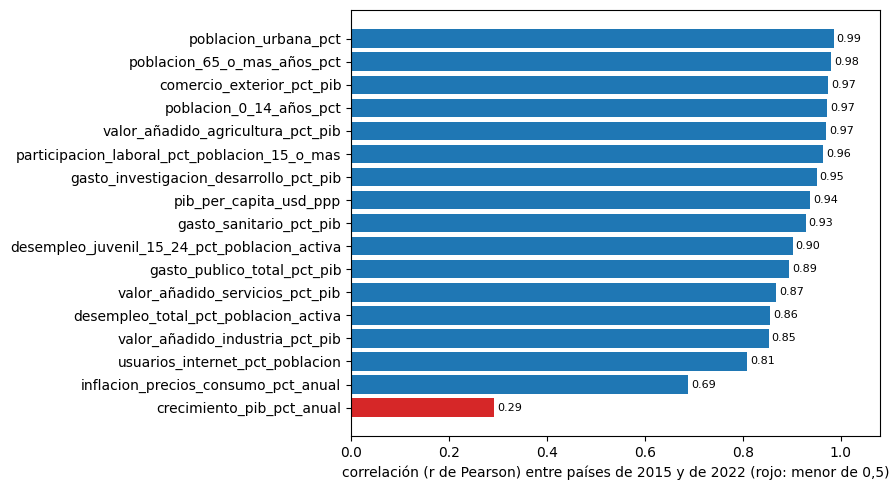

In [5]:
estabilidad = pd.Series({indicador: macro.pivot(index='pais', columns='edicion', values=indicador)[[2015, 2022]].dropna().corr().iloc[0, 1] for indicador in indicadores_macro},
                        name='correlación entre países 2015-2022').sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.barh(estabilidad.index, estabilidad, color=['tab:red' if valor < 0.5 else 'tab:blue' for valor in estabilidad])
ax.bar_label(barras, fmt='%.2f', padding=2, fontsize=8)
ax.set_xlim(0, 1.08)
ax.set_xlabel('correlación (r de Pearson) entre países de 2015 y de 2022 (rojo: menor de 0,5)')
plt.tight_layout()
plt.show()

## 4. Qué indicadores se parecen entre sí

Correlación entre indicadores, calculada con la **media de cada país** en las cuatro ediciones (una fila por país), que es la unidad con la que se agrupará después.

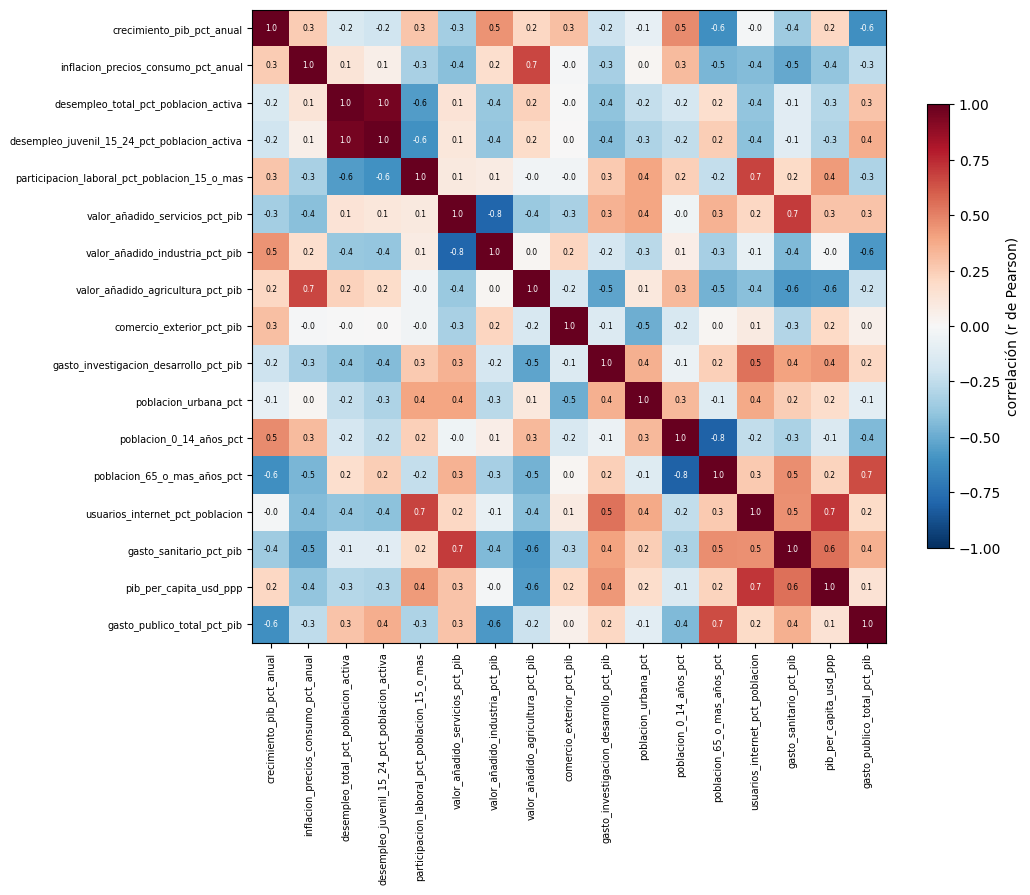

desempleo_total_pct_poblacion_activa          desempleo_juvenil_15_24_pct_poblacion_activa    0.95
poblacion_0_14_años_pct                       poblacion_65_o_mas_años_pct                    -0.81
valor_añadido_servicios_pct_pib               valor_añadido_industria_pct_pib                -0.79
usuarios_internet_pct_poblacion               pib_per_capita_usd_ppp                          0.72
valor_añadido_servicios_pct_pib               gasto_sanitario_pct_pib                         0.70
participacion_laboral_pct_poblacion_15_o_mas  usuarios_internet_pct_poblacion                 0.67
inflacion_precios_consumo_pct_anual           valor_añadido_agricultura_pct_pib               0.67
poblacion_65_o_mas_años_pct                   gasto_publico_total_pct_pib                     0.65
Name: correlación, dtype: float64

In [6]:
media_por_pais = macro.groupby('pais')[indicadores_macro].mean()
correlaciones = media_por_pais.corr()
fig, ax = plt.subplots(figsize=(11, 9))
imagen = ax.imshow(correlaciones, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(correlaciones)), correlaciones.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(correlaciones)), correlaciones.index, fontsize=7)
for fila in range(len(correlaciones)):
    for columna in range(len(correlaciones)):
        ax.text(columna, fila, f'{correlaciones.iloc[fila, columna]:.1f}', ha='center', va='center', fontsize=5.5, color='white' if abs(correlaciones.iloc[fila, columna]) > 0.6 else 'black')
fig.colorbar(imagen, ax=ax, shrink=0.7, label='correlación (r de Pearson)')
plt.tight_layout()
plt.show()

# Pares más correlacionados
pares = correlaciones.where(np.triu(np.ones(correlaciones.shape, dtype=bool), k=1)).stack().rename('correlación')
pares.reindex(pares.abs().sort_values(ascending=False).index).head(8).round(2)

## 5. Cuántas dimensiones hay: componentes principales

Análisis de componentes principales sobre la media de cada país con los indicadores estandarizados. Cada componente es una combinación de indicadores; el primero recoge la mayor parte de lo que varía a la vez.

33 países con todos los indicadores; sin alguno: []


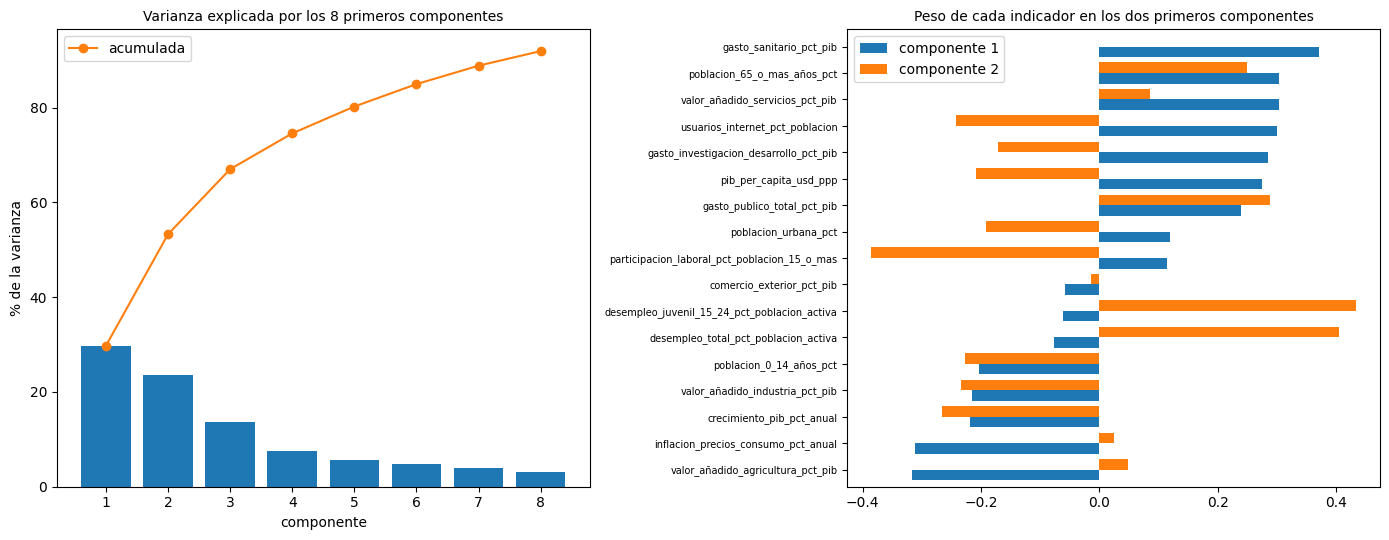

Varianza explicada (%): {'componente 1': 29.8, 'componente 2': 23.6, 'componente 3': 13.7, 'componente 4': 7.6}
Varianza acumulada de los 3 primeros componentes: 67.0 %
componente 1, indicadores de mayor peso: {'gasto_sanitario_pct_pib': 0.37, 'valor_añadido_agricultura_pct_pib': -0.32, 'inflacion_precios_consumo_pct_anual': -0.31, 'poblacion_65_o_mas_años_pct': 0.3}
componente 2, indicadores de mayor peso: {'desempleo_juvenil_15_24_pct_poblacion_activa': 0.43, 'desempleo_total_pct_poblacion_activa': 0.4, 'participacion_laboral_pct_poblacion_15_o_mas': -0.39, 'gasto_publico_total_pct_pib': 0.29}


In [7]:
paises_completos = media_por_pais.dropna()
print(f'{len(paises_completos)} países con todos los indicadores; sin alguno: {sorted(set(media_por_pais.index) - set(paises_completos.index))}')
datos_estandarizados = StandardScaler().fit_transform(paises_completos)
componentes = PCA().fit(datos_estandarizados)
varianza_explicada = pd.Series(componentes.explained_variance_ratio_, index=[f'componente {numero}' for numero in range(1, len(componentes.explained_variance_ratio_) + 1)])

fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))
ejes[0].bar(range(1, 9), 100 * varianza_explicada.iloc[:8], color='tab:blue')
ejes[0].plot(range(1, 9), 100 * varianza_explicada.cumsum().iloc[:8], marker='o', color='tab:orange', label='acumulada')
ejes[0].set_xlabel('componente')
ejes[0].set_ylabel('% de la varianza')
ejes[0].set_title('Varianza explicada por los 8 primeros componentes', fontsize=10)
ejes[0].legend()
pesos = pd.DataFrame(componentes.components_[:2].T, index=paises_completos.columns, columns=['componente 1', 'componente 2']).sort_values('componente 1')
pesos.plot.barh(ax=ejes[1], width=0.8)
ejes[1].set_title('Peso de cada indicador en los dos primeros componentes', fontsize=10)
ejes[1].tick_params(axis='y', labelsize=7)
plt.tight_layout()
plt.show()
print('Varianza explicada (%):', (100 * varianza_explicada.iloc[:4]).round(1).to_dict())
print('Varianza acumulada de los 3 primeros componentes:', round(100 * varianza_explicada.iloc[:3].sum(), 1), '%')
for componente in ['componente 1', 'componente 2']:
    mayores = pesos[componente].reindex(pesos[componente].abs().sort_values(ascending=False).index).head(4).round(2)
    print(f'{componente}, indicadores de mayor peso:', mayores.to_dict())

## 6. Relación con el rendimiento

Correlación de cada indicador con la nota media de matemáticas, **dentro de cada edición** (cada variable se estandariza por edición para que el cambio de nivel medio entre ediciones no entre en la comparación). Es solo exploratoria: una correlación no implica causa y casi todos los indicadores están ligados a la renta del país.

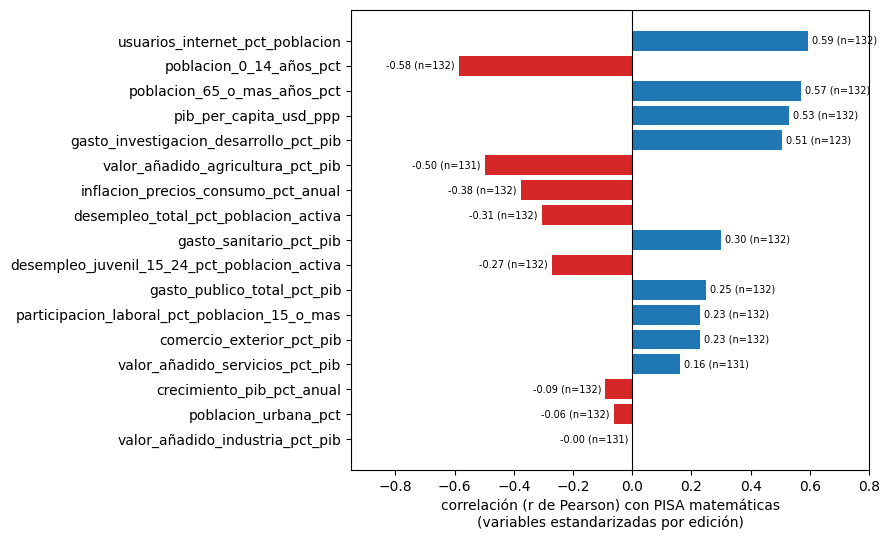

In [8]:
estandarizado_por_edicion = macro[['edicion', 'pisa_matematicas'] + indicadores_macro].copy()
estandarizado_por_edicion[['pisa_matematicas'] + indicadores_macro] = estandarizado_por_edicion.groupby('edicion')[['pisa_matematicas'] + indicadores_macro].transform(lambda columna: (columna - columna.mean()) / columna.std(ddof=0))
correlacion_con_matematicas = pd.DataFrame({indicador: {'r': estandarizado_por_edicion[['pisa_matematicas', indicador]].dropna().corr().iloc[0, 1], 'n': len(estandarizado_por_edicion[['pisa_matematicas', indicador]].dropna())}
                                            for indicador in indicadores_macro}).T.sort_values('r', key=abs)
fig, ax = plt.subplots(figsize=(9, 5.5))
barras = ax.barh(correlacion_con_matematicas.index, correlacion_con_matematicas['r'], color=['tab:blue' if valor > 0 else 'tab:red' for valor in correlacion_con_matematicas['r']])
ax.bar_label(barras, labels=[f'{correlacion:.2f} (n={int(n_observaciones)})' for correlacion, n_observaciones in zip(correlacion_con_matematicas['r'], correlacion_con_matematicas['n'])], padding=3, fontsize=7)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlim(-0.95, 0.8)
ax.set_xlabel('correlación (r de Pearson) con PISA matemáticas' + chr(10) + '(variables estandarizadas por edición)')
plt.tight_layout()
plt.show()

## 7. Perfiles de países

Agrupación de los países con K-means sobre los indicadores macro estandarizados (media de cada país en las cuatro ediciones). El número de grupos se elige por la silueta entre los que no dejan grupos de menos de 3 países. Se contrasta con una clasificación orientativa por familias de países (nórdicos, anglosajones, etc.), definida aquí a mano y que no procede de ninguna fuente.

In [9]:
siluetas, grupos_menores, etiquetas_por_k = {}, {}, {}
for numero_grupos in range(2, 9):
    etiquetas = KMeans(n_clusters=numero_grupos, random_state=42, n_init='auto').fit_predict(datos_estandarizados)
    siluetas[numero_grupos] = silhouette_score(datos_estandarizados, etiquetas)
    grupos_menores[numero_grupos] = np.bincount(etiquetas).min()
    etiquetas_por_k[numero_grupos] = etiquetas
resumen_k = pd.DataFrame({'silueta': siluetas, 'país del grupo más pequeño': grupos_menores}).rename_axis('k')
display(resumen_k.round(2))
k_elegido = int(resumen_k[resumen_k['país del grupo más pequeño'] >= 3]['silueta'].idxmax())
perfil = pd.Series(etiquetas_por_k[k_elegido], index=paises_completos.index, name='perfil')
print(f'k elegido por la silueta (grupos de al menos 3 países) = {k_elegido}')
for grupo in range(k_elegido):
    print(f'  perfil {grupo}: ' + ', '.join(perfil.index[perfil == grupo]))

,silueta,país del grupo más pequeño
k,,
2,0.17,15
3,0.18,5
4,0.18,4
5,0.20,1
6,0.13,1
7,0.14,1
8,0.17,1


k elegido por la silueta (grupos de al menos 3 países) = 3
  perfil 0: ESP, FRA, GRC, ITA, PRT
  perfil 1: CHL, IRL, ISL, ISR, MEX, NZL, POL, TUR
  perfil 2: AUS, AUT, BEL, CAN, CHE, CZE, DEU, DNK, EST, FIN, GBR, HUN, JPN, KOR, NLD, NOR, SVK, SVN, SWE, USA


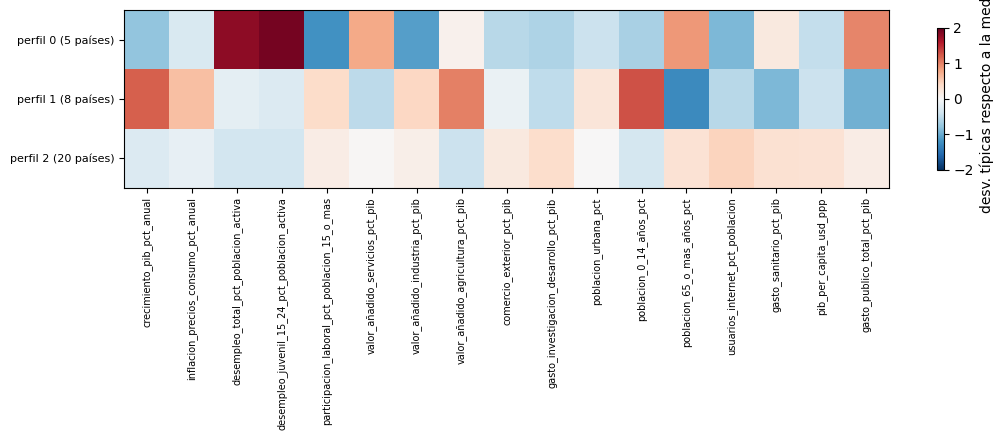

familia,Anglosajones,Centro y este de Europa,Continentales,Nórdicos,Otros,Sur de Europa y Latinoamérica
perfil,,,,,,
0,0,0,1,0,0,4
1,2,1,0,1,2,2
2,4,5,5,4,2,0


In [10]:
# Valor medio de cada perfil en cada indicador, en desviaciones típicas respecto a la media de los países
centros = pd.DataFrame(datos_estandarizados, index=paises_completos.index, columns=paises_completos.columns).groupby(perfil).mean()
fig, ax = plt.subplots(figsize=(11, 3 + 0.5 * k_elegido))
imagen = ax.imshow(centros, cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(centros.shape[1]), centros.columns, rotation=90, fontsize=7)
ax.set_yticks(range(k_elegido), [f'perfil {grupo} ({(perfil == grupo).sum()} países)' for grupo in centros.index], fontsize=8)
fig.colorbar(imagen, ax=ax, shrink=0.8, label='desv. típicas respecto a la media')
plt.tight_layout()
plt.show()

# Contraste con una clasificación orientativa por familias de países (definida a mano, no procede de ninguna fuente)
familias = {'Nórdicos': ['DNK', 'FIN', 'ISL', 'NOR', 'SWE'], 'Anglosajones': ['AUS', 'CAN', 'GBR', 'IRL', 'NZL', 'USA'],
            'Sur de Europa y Latinoamérica': ['ESP', 'ITA', 'PRT', 'GRC', 'MEX', 'CHL'], 'Continentales': ['AUT', 'BEL', 'DEU', 'FRA', 'NLD', 'CHE'],
            'Centro y este de Europa': ['CZE', 'EST', 'HUN', 'POL', 'SVK', 'SVN'], 'Otros': ['JPN', 'KOR', 'ISR', 'TUR']}
familia_de_cada_pais = pd.Series({pais: familia for familia, lista in familias.items() for pais in lista})
pd.crosstab(perfil, familia_de_cada_pais.reindex(perfil.index).rename('familia'))

## Hallazgos

* **Cobertura**: 13 de los 17 indicadores están completos en las cuatro ediciones. Faltan datos en el gasto en I+D (3 países en 2012, 2018 y 2022) y en los tres porcentajes de valor añadido (1 país en 2022).
* **Casi todo es estructural**: 15 de los 17 indicadores mantienen el orden de los países entre 2015 y 2022 (correlación de 0,81 a 0,99). Solo la inflación (0,69) y, sobre todo, el crecimiento del PIB (0,29) cambian con la coyuntura de cada año, así que una sola edición es una foto poco representativa de ellos.
* **Hay indicadores casi duplicados**: el desempleo total y el juvenil (correlación 0,95), la población de 0 a 14 años y la de 65 o más (−0,81), y el peso de los servicios y el de la industria (−0,79). También van juntos internet y el PIB per cápita (0,72).
* **No hay una sola dimensión**: el primer componente explica un 29,8 % de la varianza, el segundo un 23,6 % y el tercero un 13,7 % (67,0 % entre los tres). El primero tiene sus mayores pesos en el gasto sanitario (0,37), la agricultura (−0,32), la inflación (−0,31) y la población de 65 o más (0,30), junto a internet, I+D y PIB con peso positivo: un eje de nivel de desarrollo. El segundo está dominado por el desempleo juvenil (0,43), el desempleo total (0,40) y la participación laboral (−0,39): el mercado de trabajo.
* **Relación con el rendimiento** (dentro de cada edición): internet (0,59), población de 0 a 14 años (−0,58), población de 65 o más (0,57), PIB per cápita (0,53), I+D (0,51) y agricultura (−0,50). Los demás quedan por debajo de 0,40 en valor absoluto. Que la estructura demográfica correlacione tanto probablemente refleja el nivel de desarrollo de los países, no un efecto propio.
* **Los perfiles puramente macro son débiles**: la silueta es de 0,18 con k = 3 (entre 0,13 y 0,20 para cualquier k), mucho menos que con variables de gasto educativo. Salen un grupo con alto desempleo y mucha población mayor (España, Francia, Grecia, Italia y Portugal), otro más joven y con mayor crecimiento, más agricultura e industria y menos desarrollo (Chile, Irlanda, Islandia, Israel, México, Nueva Zelanda, Polonia y Turquía) y un tercero con 20 países cercanos a la media en casi todo. **No reproduce las familias** de países nórdicos, anglosajones o continentales; solo agrupa a cuatro de los seis países del sur de Europa y Latinoamérica que definimos.
* **Para el modelo**: las variables macro describen bien el contexto, pero no separan perfiles claros por sí solas, y no entran en el modelo de `03_modelado`. Un perfil útil exigiría elegir pocas variables por tema o combinar el macro con variables del modelo de financiación educativa.